In [1]:
# =====================================================
# SWIN-TINY — CELL 1
# Install Packages + Mount Drive + Imports + Configuration
# Dataset Auto-Detection + Output Folders
# =====================================================

!pip -q install -U timm fvcore scipy statsmodels openpyxl

from google.colab import drive
drive.mount(
    "/content/drive",
    force_remount=False
)


# =====================================================
# 1. IMPORTS
# =====================================================

import os
import gc
import time
import random
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torchvision import transforms

from torchvision.transforms import (
    InterpolationMode
)

import timm

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings(
    "ignore"
)


# =====================================================
# 2. SAME EXPERIMENTAL CONFIGURATION
# =====================================================

SEED = 42

IMG_SIZE = 224

BATCH_SIZE = 32

EPOCHS = 30

LEARNING_RATE = 1e-4

N_FOLDS = 5

THRESHOLD = 0.50

NUM_WORKERS = 2


# =====================================================
# 3. MODEL INFORMATION
# =====================================================

MODEL_NAME = "Swin-Tiny"

TIMM_MODEL_NAME = (
    "swin_tiny_patch4_window7_224.ms_in22k_ft_in1k"
)

MODEL_FOLDER_NAME = (
    "05_Swin_Tiny"
)


# =====================================================
# 4. CLASS INFORMATION
# =====================================================

CLASS_NAMES = [
    "encroachment_present",
    "no_encroachment"
]


CLASS_TO_IDX = {
    "encroachment_present": 0,
    "no_encroachment": 1
}


IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)


# =====================================================
# 5. DATASET AUTO-DETECTION
# =====================================================

SEARCH_ROOT = Path(
    "/content/drive/MyDrive/Brishty_ml/"
    "clean_dataset_brishty"
)


if not SEARCH_ROOT.exists():

    raise FileNotFoundError(
        f"Dataset search root was not found:\n"
        f"{SEARCH_ROOT}"
    )


possible_dataset_directories = []


candidate_directories = [
    SEARCH_ROOT
]


candidate_directories.extend(
    [
        path
        for path in SEARCH_ROOT.rglob("*")
        if path.is_dir()
    ]
)


for candidate_directory in candidate_directories:

    contains_all_class_folders = all(

        (
            candidate_directory /
            class_name
        ).is_dir()

        for class_name in CLASS_NAMES
    )


    if contains_all_class_folders:

        possible_dataset_directories.append(
            candidate_directory
        )


if len(
    possible_dataset_directories
) == 0:

    raise FileNotFoundError(
        "Could not find a dataset directory containing "
        "both class folders:\n"
        "'encroachment_present'\n"
        "'no_encroachment'"
    )


DATASET_DIR = (
    possible_dataset_directories[0]
)


# =====================================================
# 6. OUTPUT PATHS
# =====================================================

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Brishty_ml/"
    "reviewer_final_results"
)


OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


MODEL_OUTPUT_DIR = (
    OUTPUT_DIR /
    MODEL_FOLDER_NAME
)


MODEL_DIR = (
    MODEL_OUTPUT_DIR /
    "saved_models"
)


HISTORY_DIR = (
    MODEL_OUTPUT_DIR /
    "training_history"
)


FIGURE_DIR = (
    MODEL_OUTPUT_DIR /
    "figures"
)


PREDICTION_DIR = (
    MODEL_OUTPUT_DIR /
    "predictions"
)


METRIC_DIR = (
    MODEL_OUTPUT_DIR /
    "metrics"
)


for folder in [
    MODEL_OUTPUT_DIR,
    MODEL_DIR,
    HISTORY_DIR,
    FIGURE_DIR,
    PREDICTION_DIR,
    METRIC_DIR
]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# =====================================================
# 7. FIXED SPLIT FILE PATHS
# =====================================================

COMPLETE_SPLIT_PATH = (
    OUTPUT_DIR /
    "fixed_test_and_5fold_split.csv"
)


FOLD_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_5fold_development_set.csv"
)


TEST_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_test_set.csv"
)


# =====================================================
# 8. DEVICE
# =====================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


# =====================================================
# 9. REPRODUCIBILITY
# =====================================================

def set_seed(
    seed=42
):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(
        seed
    )


    random.seed(
        seed
    )


    np.random.seed(
        seed
    )


    torch.manual_seed(
        seed
    )


    torch.cuda.manual_seed_all(
        seed
    )


    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False


set_seed(
    SEED
)


# =====================================================
# 10. COUNT IMAGES IN THE DETECTED DATASET
# =====================================================

class_image_counts = {}


for class_name in CLASS_NAMES:

    class_folder = (
        DATASET_DIR /
        class_name
    )


    image_count = sum(

        1

        for file_path in class_folder.rglob("*")

        if (
            file_path.is_file()
            and
            file_path.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    )


    class_image_counts[
        class_name
    ] = image_count


    if image_count == 0:

        raise RuntimeError(
            f"No images were found inside:\n"
            f"{class_folder}"
        )


# =====================================================
# 11. FINAL CELL 1 CHECK
# =====================================================

print(
    "=" * 75
)

print(
    "SWIN-TINY CELL 1 COMPLETED"
)

print(
    "=" * 75
)


print(
    "Device:",
    DEVICE
)


if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(
            0
        )
    )


print(
    "Model:",
    MODEL_NAME
)


print(
    "Pretrained checkpoint:",
    TIMM_MODEL_NAME
)


print(
    "Dataset search root:",
    SEARCH_ROOT
)


print(
    "Detected dataset directory:",
    DATASET_DIR
)


print(
    "\nDataset class counts:"
)


for class_name, image_count in (
    class_image_counts.items()
):

    print(
        f"{class_name}: "
        f"{image_count}"
    )


print(
    "\nImage size:",
    IMG_SIZE
)


print(
    "Batch size:",
    BATCH_SIZE
)


print(
    "Epochs:",
    EPOCHS
)


print(
    "Learning rate:",
    LEARNING_RATE
)


print(
    "Number of folds:",
    N_FOLDS
)


print(
    "Number of workers:",
    NUM_WORKERS
)


print(
    "\nFixed development split path:"
)

print(
    FOLD_CSV_PATH
)


print(
    "\nFixed test split path:"
)

print(
    TEST_CSV_PATH
)


print(
    "\nSwin-Tiny output folder:"
)

print(
    MODEL_OUTPUT_DIR
)


print(
    "\nNo fold has been trained yet."
)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 5.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.9/65.9 kB 1.2 MB/s eta 0:00:00
Mounted at /content/drive
SWIN-TINY CELL 1 COMPLETED
Device: cuda
GPU: Tesla T4
Model: Swin-Tiny
Pretrained checkpoint: swin_tiny_patch4_window7_224.ms_in22k_ft_in1k
Dataset search root: /content/drive/MyDrive/Brishty_ml/clean_dataset_brishty
Detected dataset directory: /content/drive/MyDrive/Brishty_ml/clean_dataset_brishty/images

Dataset class counts:
encroachment_present: 3891
no_encroachment: 3520

Image size: 224
Batch size: 32
Epochs: 30
Learning rate: 0.0001
Number of folds: 5
Number of workers: 2

Fixed dev

In [2]:
# ============================================================
# SWIN-TINY — CELL 2
# Fixed Split + DataLoader + Model + Training Functions
# ============================================================


# ============================================================
# 1. COLLECT ALL DATASET IMAGES
# ============================================================

def collect_images(
    dataset_dir
):

    image_paths = []
    labels = []

    for class_name in CLASS_NAMES:

        class_folder = (
            dataset_dir /
            class_name
        )

        for root, directories, files in os.walk(
            class_folder
        ):

            directories.sort()

            for file_name in sorted(
                files
            ):

                if file_name.lower().endswith(
                    IMAGE_EXTENSIONS
                ):

                    image_path = str(
                        Path(root) /
                        file_name
                    )

                    image_paths.append(
                        image_path
                    )

                    labels.append(
                        CLASS_TO_IDX[
                            class_name
                        ]
                    )

    return (
        np.asarray(
            image_paths
        ),

        np.asarray(
            labels,
            dtype=np.int64
        )
    )


all_image_paths, all_labels = collect_images(
    DATASET_DIR
)


if len(all_image_paths) == 0:

    raise RuntimeError(
        f"No images found inside:\n"
        f"{DATASET_DIR}"
    )


print("=" * 75)
print("CLEANED DATASET SUMMARY")
print("=" * 75)

print(
    "Total images found:",
    len(all_image_paths)
)


for class_name, class_index in (
    CLASS_TO_IDX.items()
):

    class_count = int(
        np.sum(
            all_labels ==
            class_index
        )
    )

    print(
        f"{class_name}: "
        f"{class_count}"
    )


# ============================================================
# 2. CHECK WHETHER EXISTING SPLITS MATCH CURRENT DATASET
# ============================================================

def fixed_splits_are_valid():

    if not (
        FOLD_CSV_PATH.exists()
        and
        TEST_CSV_PATH.exists()
    ):

        return False


    try:

        existing_development_df = pd.read_csv(
            FOLD_CSV_PATH
        )

        existing_test_df = pd.read_csv(
            TEST_CSV_PATH
        )

    except Exception:

        return False


    required_columns = {
        "image_path",
        "label",
        "class_name",
        "dataset_role",
        "fold_id"
    }


    if not required_columns.issubset(
        existing_development_df.columns
    ):

        return False


    if not required_columns.issubset(
        existing_test_df.columns
    ):

        return False


    existing_paths = set(

        pd.concat(
            [
                existing_development_df[
                    "image_path"
                ],
                existing_test_df[
                    "image_path"
                ]
            ],
            ignore_index=True
        )
        .astype(str)
        .tolist()
    )


    current_paths = set(
        all_image_paths
        .astype(str)
        .tolist()
    )


    return (
        existing_paths ==
        current_paths
    )


# ============================================================
# 3. LOAD OR CREATE SAME FIXED SPLITS
# ============================================================

if fixed_splits_are_valid():

    print(
        "\nMatching fixed split files found."
    )

    print(
        "Existing fixed test set and folds "
        "will be reused."
    )


    development_df = pd.read_csv(
        FOLD_CSV_PATH
    )

    test_df = pd.read_csv(
        TEST_CSV_PATH
    )


else:

    print(
        "\nMatching fixed split files were not found."
    )

    print(
        "Creating fixed split files using "
        "the same settings."
    )


    # --------------------------------------------------------
    # Fixed 15% independent test set
    # --------------------------------------------------------

    (
        development_paths,
        test_paths,
        development_labels,
        test_labels
    ) = train_test_split(

        all_image_paths,
        all_labels,

        test_size=0.15,

        random_state=SEED,

        stratify=all_labels,

        shuffle=True
    )


    # --------------------------------------------------------
    # Fixed stratified five-fold assignment
    # --------------------------------------------------------

    development_fold_ids = np.zeros(
        len(
            development_paths
        ),
        dtype=np.int64
    )


    stratified_kfold = StratifiedKFold(

        n_splits=N_FOLDS,

        shuffle=True,

        random_state=SEED
    )


    for fold_number, (
        _,
        validation_indices
    ) in enumerate(

        stratified_kfold.split(
            development_paths,
            development_labels
        ),

        start=1
    ):

        development_fold_ids[
            validation_indices
        ] = fold_number


    if np.any(
        development_fold_ids == 0
    ):

        raise RuntimeError(
            "Some development images were not "
            "assigned to a fold."
        )


    development_df = pd.DataFrame({

        "image_path":
            development_paths,

        "label":
            development_labels.astype(
                int
            ),

        "class_name": [
            CLASS_NAMES[
                int(label)
            ]
            for label in
            development_labels
        ],

        "dataset_role":
            "development",

        "fold_id":
            development_fold_ids
    })


    test_df = pd.DataFrame({

        "image_path":
            test_paths,

        "label":
            test_labels.astype(
                int
            ),

        "class_name": [
            CLASS_NAMES[
                int(label)
            ]
            for label in
            test_labels
        ],

        "dataset_role":
            "test",

        "fold_id":
            0
    })


    complete_split_df = pd.concat(
        [
            development_df,
            test_df
        ],
        ignore_index=True
    )


    development_df.to_csv(
        FOLD_CSV_PATH,
        index=False
    )

    test_df.to_csv(
        TEST_CSV_PATH,
        index=False
    )

    complete_split_df.to_csv(
        COMPLETE_SPLIT_PATH,
        index=False
    )


    print(
        "Fixed split files created successfully."
    )


# ============================================================
# 4. STANDARDIZE AND VERIFY SPLITS
# ============================================================

development_df[
    "label"
] = (
    development_df[
        "label"
    ]
    .astype(int)
)


development_df[
    "fold_id"
] = (
    development_df[
        "fold_id"
    ]
    .astype(int)
)


test_df[
    "label"
] = (
    test_df[
        "label"
    ]
    .astype(int)
)


available_folds = sorted(
    development_df[
        "fold_id"
    ]
    .unique()
    .tolist()
)


if available_folds != [
    1,
    2,
    3,
    4,
    5
]:

    raise ValueError(
        f"Unexpected fold IDs: "
        f"{available_folds}"
    )


missing_development = int(

    (
        ~development_df[
            "image_path"
        ].apply(
            lambda path:
                Path(path).exists()
        )
    ).sum()
)


missing_test = int(

    (
        ~test_df[
            "image_path"
        ].apply(
            lambda path:
                Path(path).exists()
        )
    ).sum()
)


if missing_development > 0:

    raise FileNotFoundError(
        f"{missing_development} development "
        f"images are missing."
    )


if missing_test > 0:

    raise FileNotFoundError(
        f"{missing_test} test images are missing."
    )


print(
    "\nDevelopment images:",
    len(
        development_df
    )
)


print(
    "Independent test images:",
    len(
        test_df
    )
)


print(
    "Fold IDs:",
    available_folds
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    fold_train_df = development_df[
        development_df[
            "fold_id"
        ] != fold_number
    ]


    fold_validation_df = development_df[
        development_df[
            "fold_id"
        ] == fold_number
    ]


    print(
        f"\nFold {fold_number}:"
    )


    print(
        "  Training images:",
        len(
            fold_train_df
        )
    )


    print(
        "  Validation images:",
        len(
            fold_validation_df
        )
    )


# ============================================================
# 5. PREPROCESSING
# Same experimental augmentation as other models
# ============================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]


IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


train_transform = transforms.Compose([

    transforms.Resize(
        (
            IMG_SIZE,
            IMG_SIZE
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.RandomHorizontalFlip(
        p=0.50
    ),

    transforms.RandomRotation(
        degrees=36,
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.RandomAffine(
        degrees=0,
        scale=(
            0.90,
            1.10
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


evaluation_transform = transforms.Compose([

    transforms.Resize(
        (
            IMG_SIZE,
            IMG_SIZE
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================================
# 6. DATASET CLASS
# ============================================================

class SEVDDataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(
                drop=True
            )
            .copy()
        )

        self.transform = transform


    def __len__(
        self
    ):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        row = self.dataframe.iloc[
            index
        ]


        image_path = str(
            row[
                "image_path"
            ]
        )


        label = float(
            row[
                "label"
            ]
        )


        try:

            with Image.open(
                image_path
            ) as opened_image:

                image = opened_image.convert(
                    "RGB"
                )

        except Exception as error:

            raise RuntimeError(
                f"Unable to load image:\n"
                f"{image_path}"
            ) from error


        if self.transform is not None:

            image = self.transform(
                image
            )


        return {

            "image":
                image,

            "label":
                torch.tensor(
                    label,
                    dtype=torch.float32
                ),

            "image_path":
                image_path
        }


# ============================================================
# 7. DATALOADER CREATOR
# ============================================================

def create_dataloader(
    dataframe,
    transform,
    shuffle,
    fold_seed=SEED
):

    dataset = SEVDDataset(
        dataframe=dataframe,
        transform=transform
    )


    generator = torch.Generator()

    generator.manual_seed(
        fold_seed
    )


    dataloader = DataLoader(

        dataset,

        batch_size=BATCH_SIZE,

        shuffle=shuffle,

        num_workers=NUM_WORKERS,

        pin_memory=torch.cuda.is_available(),

        persistent_workers=(
            NUM_WORKERS > 0
        ),

        drop_last=False,

        generator=(
            generator
            if shuffle
            else None
        )
    )


    return (
        dataset,
        dataloader
    )


test_dataset, test_loader = (
    create_dataloader(

        dataframe=test_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=SEED
    )
)


# ============================================================
# 8. SWIN-TINY BINARY CLASSIFIER
# ============================================================

class SwinTinyBinaryClassifier(
    nn.Module
):

    def __init__(
        self,
        dropout_rate=0.4
    ):

        super().__init__()


        self.backbone = timm.create_model(

            TIMM_MODEL_NAME,

            pretrained=True,

            num_classes=0,

            global_pool="avg"
        )


        # Freeze the entire pretrained backbone.
        # Same policy used for the other models.

        for parameter in (
            self.backbone.parameters()
        ):

            parameter.requires_grad = False


        self.feature_dimension = (
            self.backbone.num_features
        )


        self.dropout = nn.Dropout(
            p=dropout_rate
        )


        self.binary_output = nn.Linear(
            self.feature_dimension,
            1
        )


    def forward(
        self,
        images
    ):

        features = self.backbone(
            images
        )


        features = self.dropout(
            features
        )


        logits = self.binary_output(
            features
        )


        return logits.squeeze(
            dim=1
        )


def build_swin_tiny_model():

    model = SwinTinyBinaryClassifier(
        dropout_rate=0.4
    ).to(
        DEVICE
    )


    criterion = (
        nn.BCEWithLogitsLoss()
    )


    optimizer = torch.optim.Adam(

        filter(
            lambda parameter:
                parameter.requires_grad,

            model.parameters()
        ),

        lr=LEARNING_RATE
    )


    return (
        model,
        criterion,
        optimizer
    )


# ============================================================
# 9. TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    epoch_number
):

    model.train()


    # Keep frozen backbone in evaluation mode.

    model.backbone.eval()


    running_loss = 0.0

    all_labels = []

    all_predictions = []


    progress_bar = tqdm(

        dataloader,

        desc=(
            f"Epoch {epoch_number:02d}/"
            f"{EPOCHS} Training"
        ),

        leave=False
    )


    for batch in progress_bar:

        images = batch[
            "image"
        ].to(
            DEVICE,
            non_blocking=True
        )


        labels = batch[
            "label"
        ].to(
            DEVICE,
            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        logits = model(
            images
        )


        loss = criterion(
            logits,
            labels
        )


        loss.backward()

        optimizer.step()


        probabilities = torch.sigmoid(
            logits
        )


        predictions = (
            probabilities >=
            THRESHOLD
        ).long()


        batch_size = images.size(
            0
        )


        running_loss += (
            loss.item() *
            batch_size
        )


        all_labels.extend(

            labels.detach()
            .cpu()
            .numpy()
            .astype(int)
            .tolist()
        )


        all_predictions.extend(

            predictions.detach()
            .cpu()
            .numpy()
            .astype(int)
            .tolist()
        )


        progress_bar.set_postfix(
            loss=(
                f"{loss.item():.4f}"
            )
        )


    epoch_loss = (
        running_loss /
        len(
            dataloader.dataset
        )
    )


    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )


    return {

        "loss":
            float(
                epoch_loss
            ),

        "accuracy":
            float(
                epoch_accuracy
            )
    }


# ============================================================
# 10. EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    model,
    dataloader,
    criterion,
    description="Validation"
):

    model.eval()


    running_loss = 0.0

    all_labels = []

    all_probabilities = []

    all_predictions = []

    all_image_paths = []


    progress_bar = tqdm(

        dataloader,

        desc=description,

        leave=False
    )


    with torch.no_grad():

        for batch in progress_bar:

            images = batch[
                "image"
            ].to(
                DEVICE,
                non_blocking=True
            )


            labels = batch[
                "label"
            ].to(
                DEVICE,
                non_blocking=True
            )


            logits = model(
                images
            )


            loss = criterion(
                logits,
                labels
            )


            probabilities = torch.sigmoid(
                logits
            )


            predictions = (
                probabilities >=
                THRESHOLD
            ).long()


            batch_size = images.size(
                0
            )


            running_loss += (
                loss.item() *
                batch_size
            )


            all_labels.extend(

                labels.cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            all_probabilities.extend(

                probabilities.cpu()
                .numpy()
                .tolist()
            )


            all_predictions.extend(

                predictions.cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            all_image_paths.extend(
                batch[
                    "image_path"
                ]
            )


    labels_array = np.asarray(
        all_labels,
        dtype=int
    )


    probabilities_array = np.asarray(
        all_probabilities,
        dtype=float
    )


    predictions_array = np.asarray(
        all_predictions,
        dtype=int
    )


    confusion = confusion_matrix(

        labels_array,

        predictions_array,

        labels=[
            0,
            1
        ]
    )


    return {

        "loss":
            float(
                running_loss /
                len(
                    dataloader.dataset
                )
            ),

        "accuracy":
            float(
                accuracy_score(
                    labels_array,
                    predictions_array
                )
            ),

        "precision":
            float(
                precision_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "recall":
            float(
                recall_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "f1_score":
            float(
                f1_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "auc":
            float(
                roc_auc_score(
                    labels_array,
                    probabilities_array
                )
            ),

        "true_negative":
            int(
                confusion[
                    0,
                    0
                ]
            ),

        "false_positive":
            int(
                confusion[
                    0,
                    1
                ]
            ),

        "false_negative":
            int(
                confusion[
                    1,
                    0
                ]
            ),

        "true_positive":
            int(
                confusion[
                    1,
                    1
                ]
            ),

        "true_labels":
            labels_array,

        "probabilities":
            probabilities_array,

        "predictions":
            predictions_array,

        "image_paths":
            np.asarray(
                all_image_paths,
                dtype=str
            )
    }


# ============================================================
# 11. COMPLETE SAFETY CHECK
# ============================================================

CHECK_FOLD = 1


check_train_df = development_df[
    development_df[
        "fold_id"
    ] != CHECK_FOLD
].reset_index(
    drop=True
)


check_validation_df = development_df[
    development_df[
        "fold_id"
    ] == CHECK_FOLD
].reset_index(
    drop=True
)


check_train_dataset, check_train_loader = (
    create_dataloader(

        dataframe=check_train_df,

        transform=train_transform,

        shuffle=True,

        fold_seed=(
            SEED +
            CHECK_FOLD
        )
    )
)


check_validation_dataset, check_validation_loader = (
    create_dataloader(

        dataframe=check_validation_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=(
            SEED +
            CHECK_FOLD
        )
    )
)


sample_batch = next(
    iter(
        check_train_loader
    )
)


verification_model, _, _ = (
    build_swin_tiny_model()
)


verification_model.eval()


with torch.no_grad():

    dummy_output = verification_model(

        sample_batch[
            "image"
        ][:2].to(
            DEVICE
        )
    )


total_parameters = sum(

    parameter.numel()

    for parameter in
    verification_model.parameters()
)


trainable_parameters = sum(

    parameter.numel()

    for parameter in
    verification_model.parameters()

    if parameter.requires_grad
)


backbone_trainable_parameters = sum(

    parameter.numel()

    for parameter in
    verification_model.backbone.parameters()

    if parameter.requires_grad
)


assert sample_batch[
    "image"
].shape[
    1:
] == (
    3,
    IMG_SIZE,
    IMG_SIZE
)


assert dummy_output.shape == (
    2,
)


assert backbone_trainable_parameters == 0


print(
    "\n" +
    "=" * 75
)

print(
    "SWIN-TINY CELL 2 COMPLETED"
)

print(
    "=" * 75
)


print(
    "Dataset:",
    DATASET_DIR
)


print(
    "Development images:",
    len(
        development_df
    )
)


print(
    "Independent test images:",
    len(
        test_df
    )
)


print(
    "Fold IDs:",
    available_folds
)


print(
    "Fold 1 training images:",
    len(
        check_train_dataset
    )
)


print(
    "Fold 1 validation images:",
    len(
        check_validation_dataset
    )
)


print(
    "Training batch shape:",
    sample_batch[
        "image"
    ].shape
)


print(
    "Model:",
    MODEL_NAME
)


print(
    "Checkpoint:",
    TIMM_MODEL_NAME
)


print(
    "Feature dimension:",
    verification_model.feature_dimension
)


print(
    "Total parameters:",
    f"{total_parameters:,}"
)


print(
    "Trainable parameters:",
    f"{trainable_parameters:,}"
)


print(
    "Backbone frozen:",
    backbone_trainable_parameters == 0
)


print(
    "Dummy output shape:",
    dummy_output.shape
)


print(
    "Output folder:",
    MODEL_OUTPUT_DIR
)


print(
    "\nNo fold has been trained yet."
)


del verification_model

del check_train_loader
del check_validation_loader

del check_train_dataset
del check_validation_dataset


gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()

CLEANED DATASET SUMMARY
Total images found: 7411
encroachment_present: 3891
no_encroachment: 3520

Matching fixed split files were not found.
Creating fixed split files using the same settings.
Fixed split files created successfully.

Development images: 6299
Independent test images: 1112
Fold IDs: [1, 2, 3, 4, 5]

Fold 1:
  Training images: 5039
  Validation images: 1260

Fold 2:
  Training images: 5039
  Validation images: 1260

Fold 3:
  Training images: 5039
  Validation images: 1260

Fold 4:
  Training images: 5039
  Validation images: 1260

Fold 5:
  Training images: 5040
  Validation images: 1259


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            


SWIN-TINY CELL 2 COMPLETED
Dataset: /content/drive/MyDrive/Brishty_ml/clean_dataset_brishty/images
Development images: 6299
Independent test images: 1112
Fold IDs: [1, 2, 3, 4, 5]
Fold 1 training images: 5039
Fold 1 validation images: 1260
Training batch shape: torch.Size([32, 3, 224, 224])
Model: Swin-Tiny
Checkpoint: swin_tiny_patch4_window7_224.ms_in22k_ft_in1k
Feature dimension: 768
Total parameters: 27,520,123
Trainable parameters: 769
Backbone frozen: True
Dummy output shape: torch.Size([2])
Output folder: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny

No fold has been trained yet.



STARTING Swin-Tiny FOLD 1/5
Training images: 5039
Validation images: 1260
Independent test images: 1112

Training class distribution:
class_name
encroachment_present    2646
no_encroachment         2393
Name: count, dtype: int64

Validation class distribution:
class_name
encroachment_present    661
no_encroachment         599
Name: count, dtype: int64


Epoch 01/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 01/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 1 | Epoch 01/30 - loss: 0.4760 - accuracy: 0.8555 - val_loss: 0.3166 - val_accuracy: 0.9675


Epoch 02/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

...

Epoch 30/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 30/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 1 | Epoch 30/30 - loss: 0.0416 - accuracy: 0.9905 - val_loss: 0.0324 - val_accuracy: 0.9921

Fold 1 training time: 88.72 minutes


Fold 1 Final Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 1 Independent Test:   0%|          | 0/35 [00:00<?, ?it/s]

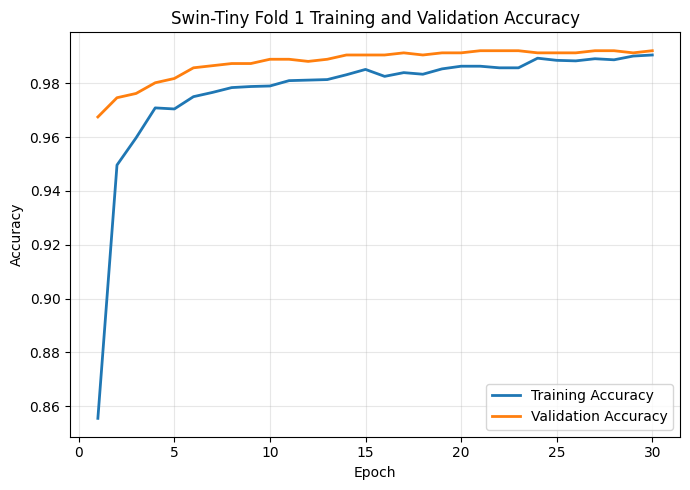

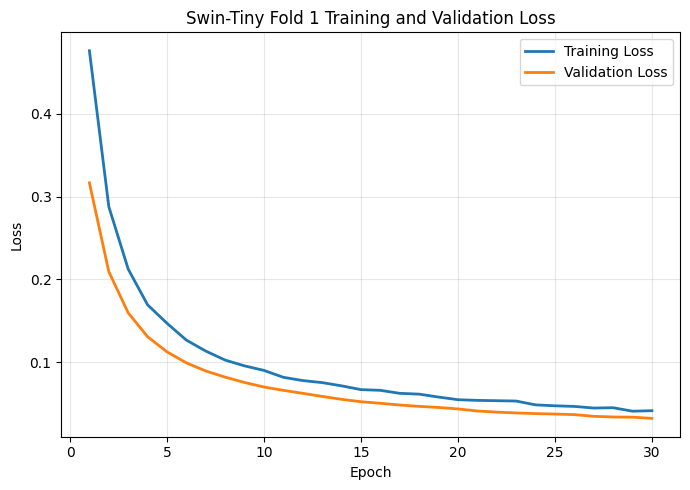


Validation result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
0,Swin-Tiny,1,validation,0.032396,0.992063,0.985173,0.998331,0.991708,0.999752,652,9,1,598,5323.265269,88.721088



Independent test result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
1,Swin-Tiny,1,test,0.032442,0.992806,0.986891,0.998106,0.992467,0.999377,577,7,1,527,5323.265269,88.721088



Saved model:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/saved_models/Swin-Tiny_fold_1.pth
Saved history:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/training_history/Swin-Tiny_fold_1_history.csv
Saved validation predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/predictions/Swin-Tiny_fold_1_validation_predictions.csv
Saved test predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/predictions/Swin-Tiny_fold_1_test_predictions.csv
Saved fold summary:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/metrics/Swin-Tiny_fold_1_summary.csv

Swin-Tiny FOLD 1 COMPLETED

STARTING Swin-Tiny FOLD 2/5
Training images: 5039
Validation images: 1260
Independent test images: 1112

Training class distribution:
class_name
encroachment_present    2646
no_encroachment         2393
Name: count, dtype: int64

Validation class distribution:
class_name
encroachment_present   

...

Epoch 30/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 30/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 2 | Epoch 30/30 - loss: 0.0437 - accuracy: 0.9891 - val_loss: 0.0307 - val_accuracy: 0.9937

Fold 2 training time: 77.55 minutes


Fold 2 Final Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 2 Independent Test:   0%|          | 0/35 [00:00<?, ?it/s]

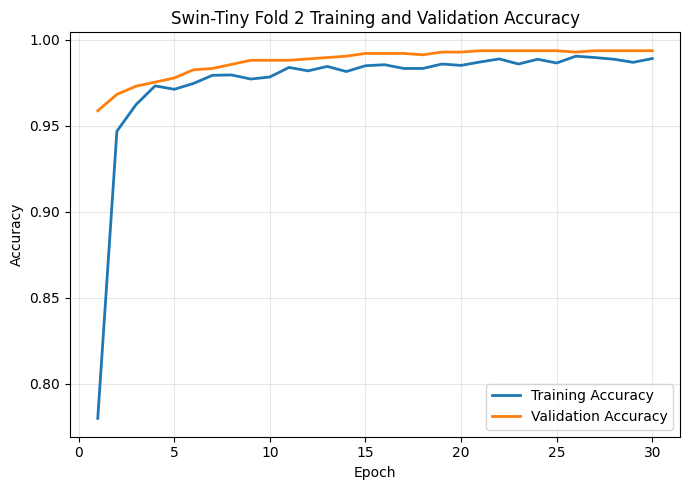

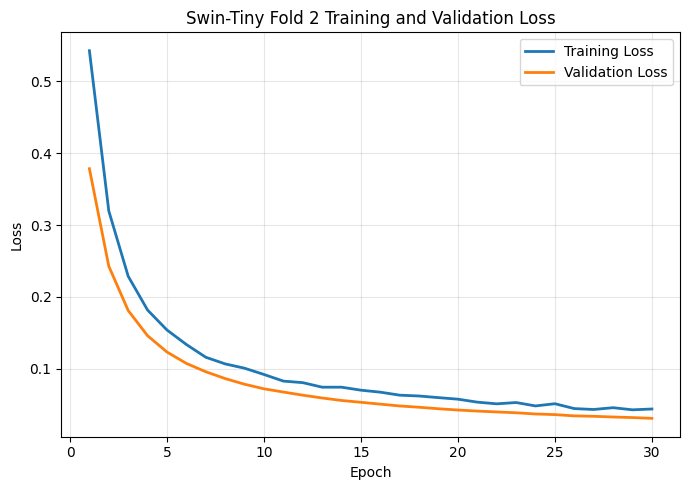


Validation result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
0,Swin-Tiny,2,validation,0.030681,0.993651,0.98843,0.998331,0.993355,0.999768,654,7,1,598,4652.707742,77.545129



Independent test result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
1,Swin-Tiny,2,test,0.032187,0.993705,0.988743,0.998106,0.993402,0.999381,578,6,1,527,4652.707742,77.545129



Saved model:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/saved_models/Swin-Tiny_fold_2.pth
Saved history:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/training_history/Swin-Tiny_fold_2_history.csv
Saved validation predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/predictions/Swin-Tiny_fold_2_validation_predictions.csv
Saved test predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/predictions/Swin-Tiny_fold_2_test_predictions.csv
Saved fold summary:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/metrics/Swin-Tiny_fold_2_summary.csv

Swin-Tiny FOLD 2 COMPLETED

STARTING Swin-Tiny FOLD 3/5
Training images: 5039
Validation images: 1260
Independent test images: 1112

Training class distribution:
class_name
encroachment_present    2645
no_encroachment         2394
Name: count, dtype: int64

Validation class distribution:
class_name
encroachment_present   

...

Epoch 30/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 30/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 3 | Epoch 30/30 - loss: 0.0427 - accuracy: 0.9887 - val_loss: 0.0325 - val_accuracy: 0.9929

Fold 3 training time: 78.21 minutes


Fold 3 Final Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 3 Independent Test:   0%|          | 0/35 [00:00<?, ?it/s]

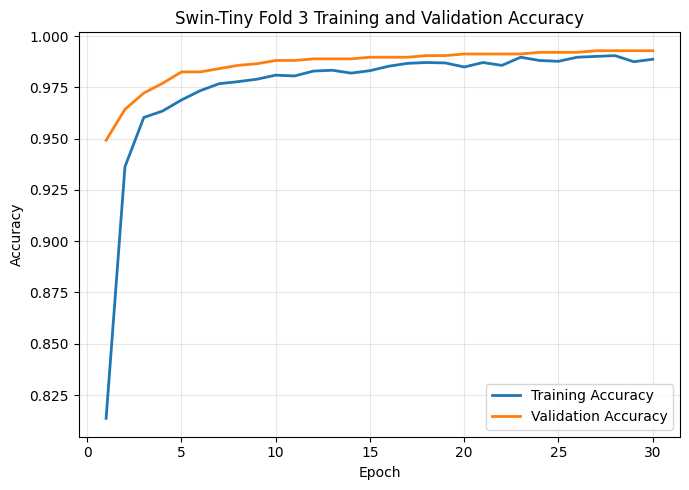

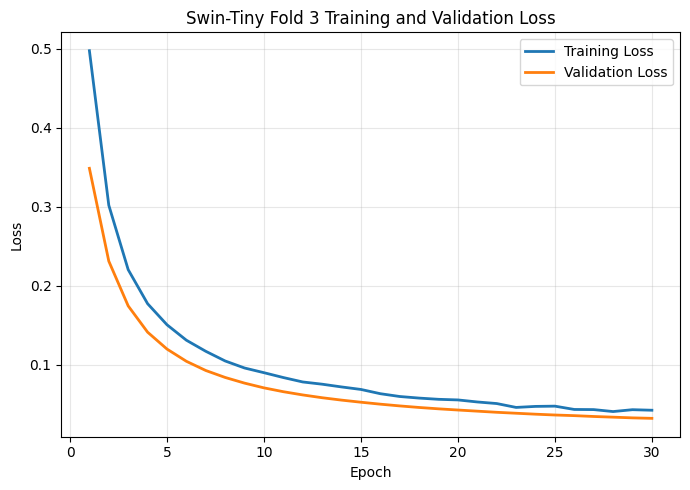


Validation result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
0,Swin-Tiny,3,validation,0.032477,0.992857,0.988391,0.996656,0.992506,0.999348,655,7,2,596,4692.569784,78.209496



Independent test result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
1,Swin-Tiny,3,test,0.031639,0.992806,0.988722,0.996212,0.992453,0.999452,578,6,2,526,4692.569784,78.209496



Saved model:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/saved_models/Swin-Tiny_fold_3.pth
Saved history:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/training_history/Swin-Tiny_fold_3_history.csv
Saved validation predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/predictions/Swin-Tiny_fold_3_validation_predictions.csv
Saved test predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/predictions/Swin-Tiny_fold_3_test_predictions.csv
Saved fold summary:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/metrics/Swin-Tiny_fold_3_summary.csv

Swin-Tiny FOLD 3 COMPLETED

STARTING Swin-Tiny FOLD 4/5
Training images: 5039
Validation images: 1260
Independent test images: 1112

Training class distribution:
class_name
encroachment_present    2645
no_encroachment         2394
Name: count, dtype: int64

Validation class distribution:
class_name
encroachment_present   

...

Epoch 30/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 30/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 4 | Epoch 30/30 - loss: 0.0440 - accuracy: 0.9889 - val_loss: 0.0278 - val_accuracy: 0.9952

Fold 4 training time: 74.18 minutes


Fold 4 Final Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 4 Independent Test:   0%|          | 0/35 [00:00<?, ?it/s]

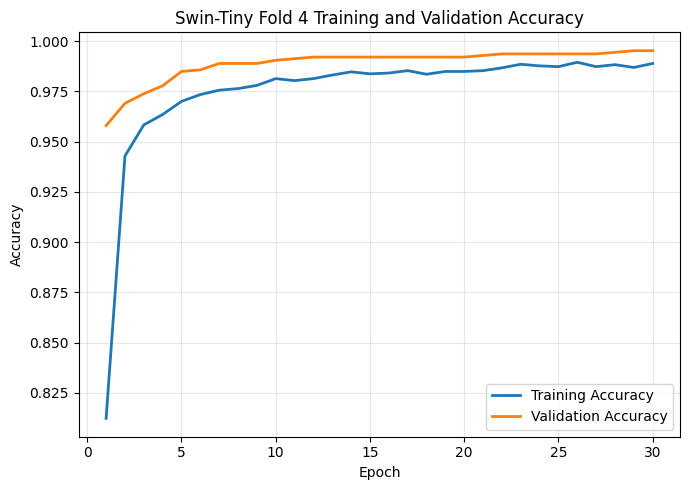

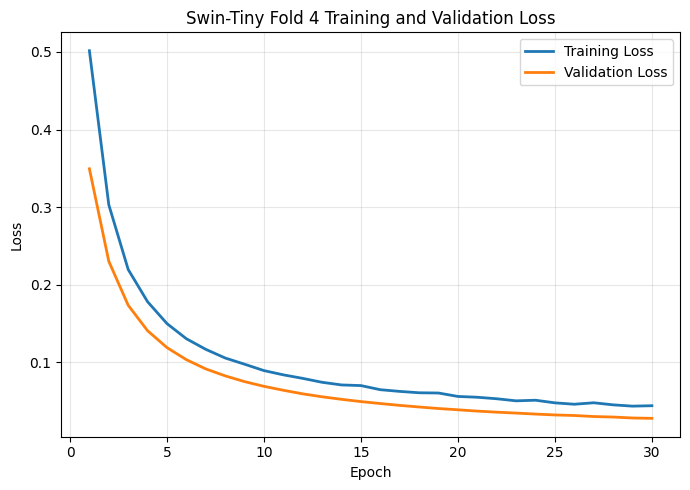


Validation result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
0,Swin-Tiny,4,validation,0.027769,0.995238,0.991694,0.998328,0.995,0.999891,657,5,1,597,4450.625939,74.177099



Independent test result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
1,Swin-Tiny,4,test,0.032844,0.993705,0.988743,0.998106,0.993402,0.999387,578,6,1,527,4450.625939,74.177099



Saved model:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/saved_models/Swin-Tiny_fold_4.pth
Saved history:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/training_history/Swin-Tiny_fold_4_history.csv
Saved validation predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/predictions/Swin-Tiny_fold_4_validation_predictions.csv
Saved test predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/predictions/Swin-Tiny_fold_4_test_predictions.csv
Saved fold summary:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/05_Swin_Tiny/metrics/Swin-Tiny_fold_4_summary.csv

Swin-Tiny FOLD 4 COMPLETED

STARTING Swin-Tiny FOLD 5/5
Training images: 5040
Validation images: 1259
Independent test images: 1112

Training class distribution:
class_name
encroachment_present    2646
no_encroachment         2394
Name: count, dtype: int64

Validation class distribution:
class_name
encroachment_present   

...

Fold 5 | Epoch 05/30 - loss: 0.1501 - accuracy: 0.9738 - val_loss: 0.1193 - val_accuracy: 0.9833


Epoch 06/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 06/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 5 | Epoch 06/30 - loss: 0.1314 - accuracy: 0.9746 - val_loss: 0.1043 - val_accuracy: 0.9841


Epoch 07/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

In [ ]:
# ============================================================
# SWIN-TINY — CELL 3
# Train, Evaluate and Save Folds 1–5
# ============================================================


# ============================================================
# 1. SAVE TRAINING HISTORY AND FOLD GRAPHS
# ============================================================

def save_history_and_graphs(
    history_dictionary,
    fold_number
):

    history_df = pd.DataFrame(
        history_dictionary
    )

    history_df.insert(
        0,
        "epoch",
        np.arange(
            1,
            len(history_df) + 1
        )
    )


    history_path = (
        HISTORY_DIR /
        f"Swin-Tiny_fold_{fold_number}_history.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )


    # Accuracy graph

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        history_df["epoch"],
        history_df["accuracy"],
        linewidth=2,
        label="Training Accuracy"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_accuracy"],
        linewidth=2,
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.title(
        f"Swin-Tiny Fold {fold_number} "
        f"Training and Validation Accuracy"
    )

    plt.legend()
    plt.grid(alpha=0.30)
    plt.tight_layout()


    accuracy_path = (
        FIGURE_DIR /
        f"Swin-Tiny_fold_{fold_number}_accuracy.png"
    )

    plt.savefig(
        accuracy_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


    # Loss graph

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        history_df["epoch"],
        history_df["loss"],
        linewidth=2,
        label="Training Loss"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        linewidth=2,
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.title(
        f"Swin-Tiny Fold {fold_number} "
        f"Training and Validation Loss"
    )

    plt.legend()
    plt.grid(alpha=0.30)
    plt.tight_layout()


    loss_path = (
        FIGURE_DIR /
        f"Swin-Tiny_fold_{fold_number}_loss.png"
    )

    plt.savefig(
        loss_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


    return {
        "history_dataframe":
            history_df,

        "history_path":
            history_path,

        "accuracy_path":
            accuracy_path,

        "loss_path":
            loss_path
    }


# ============================================================
# 2. SAVE VALIDATION OR TEST PREDICTIONS
# ============================================================

def save_predictions(
    evaluation_result,
    fold_number,
    dataset_name
):

    prediction_df = pd.DataFrame({

        "image_path":
            evaluation_result[
                "image_paths"
            ],

        "label":
            evaluation_result[
                "true_labels"
            ],

        "class_name": [
            CLASS_NAMES[int(label)]
            for label in
            evaluation_result[
                "true_labels"
            ]
        ],

        "predicted_probability_class_1":
            evaluation_result[
                "probabilities"
            ],

        "predicted_label":
            evaluation_result[
                "predictions"
            ],

        "predicted_class_name": [
            CLASS_NAMES[int(label)]
            for label in
            evaluation_result[
                "predictions"
            ]
        ]
    })


    prediction_df[
        "correct_prediction"
    ] = (
        prediction_df[
            "label"
        ].astype(int)
        ==
        prediction_df[
            "predicted_label"
        ].astype(int)
    )


    prediction_path = (
        PREDICTION_DIR /
        f"Swin-Tiny_fold_{fold_number}_"
        f"{dataset_name}_predictions.csv"
    )


    prediction_df.to_csv(
        prediction_path,
        index=False
    )


    return (
        prediction_df,
        prediction_path
    )


# ============================================================
# 3. SAVE MODEL CHECKPOINT
# ============================================================

def save_checkpoint(
    model,
    fold_number
):

    checkpoint_path = (
        MODEL_DIR /
        f"Swin-Tiny_fold_{fold_number}.pth"
    )


    checkpoint = {

        "model_name":
            MODEL_NAME,

        "timm_model_name":
            TIMM_MODEL_NAME,

        "fold":
            int(fold_number),

        "image_size":
            IMG_SIZE,

        "batch_size":
            BATCH_SIZE,

        "epochs":
            EPOCHS,

        "learning_rate":
            LEARNING_RATE,

        "threshold":
            THRESHOLD,

        "class_names":
            CLASS_NAMES,

        "class_to_idx":
            CLASS_TO_IDX,

        "model_state_dict":
            model.state_dict()
    }


    torch.save(
        checkpoint,
        checkpoint_path
    )


    return checkpoint_path


# ============================================================
# 4. CREATE FOLD SUMMARY ROW
# ============================================================

def create_summary_row(
    evaluation_result,
    fold_number,
    dataset_name,
    training_time_seconds
):

    return {

        "model":
            MODEL_NAME,

        "fold":
            int(fold_number),

        "dataset":
            dataset_name,

        "loss":
            float(
                evaluation_result[
                    "loss"
                ]
            ),

        "accuracy":
            float(
                evaluation_result[
                    "accuracy"
                ]
            ),

        "precision":
            float(
                evaluation_result[
                    "precision"
                ]
            ),

        "recall":
            float(
                evaluation_result[
                    "recall"
                ]
            ),

        "f1_score":
            float(
                evaluation_result[
                    "f1_score"
                ]
            ),

        "auc":
            float(
                evaluation_result[
                    "auc"
                ]
            ),

        "true_negative":
            int(
                evaluation_result[
                    "true_negative"
                ]
            ),

        "false_positive":
            int(
                evaluation_result[
                    "false_positive"
                ]
            ),

        "false_negative":
            int(
                evaluation_result[
                    "false_negative"
                ]
            ),

        "true_positive":
            int(
                evaluation_result[
                    "true_positive"
                ]
            ),

        "training_time_seconds":
            float(
                training_time_seconds
            ),

        "training_time_minutes":
            float(
                training_time_seconds /
                60
            )
    }


# ============================================================
# 5. TRAIN ALL FIVE FOLDS
# ============================================================

all_summary_rows = []

completed_fold_results = {}


for fold_number in range(
    1,
    N_FOLDS + 1
):

    print(
        "\n" +
        "=" * 80
    )

    print(
        f"STARTING Swin-Tiny "
        f"FOLD {fold_number}/{N_FOLDS}"
    )

    print(
        "=" * 80
    )


    # Fold-specific DataFrames

    fold_train_df = (
        development_df[
            development_df[
                "fold_id"
            ] != fold_number
        ]
        .reset_index(
            drop=True
        )
    )


    fold_validation_df = (
        development_df[
            development_df[
                "fold_id"
            ] == fold_number
        ]
        .reset_index(
            drop=True
        )
    )


    print(
        "Training images:",
        len(
            fold_train_df
        )
    )

    print(
        "Validation images:",
        len(
            fold_validation_df
        )
    )

    print(
        "Independent test images:",
        len(
            test_df
        )
    )


    print(
        "\nTraining class distribution:"
    )

    print(
        fold_train_df[
            "class_name"
        ].value_counts()
    )


    print(
        "\nValidation class distribution:"
    )

    print(
        fold_validation_df[
            "class_name"
        ].value_counts()
    )


    # Create fold DataLoaders

    (
        fold_train_dataset,
        fold_train_loader
    ) = create_dataloader(

        dataframe=fold_train_df,

        transform=train_transform,

        shuffle=True,

        fold_seed=(
            SEED +
            fold_number
        )
    )


    (
        fold_validation_dataset,
        fold_validation_loader
    ) = create_dataloader(

        dataframe=fold_validation_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=(
            SEED +
            fold_number
        )
    )


    # Reset seed and memory

    set_seed(
        SEED +
        fold_number
    )

    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    # Build fresh Swin-Tiny

    model, criterion, optimizer = (
        build_swin_tiny_model()
    )


    history_dictionary = {

        "loss": [],

        "accuracy": [],

        "val_loss": [],

        "val_accuracy": []
    }


    training_start_time = (
        time.perf_counter()
    )


    # Train full epochs

    for epoch_number in range(
        1,
        EPOCHS + 1
    ):

        training_result = train_one_epoch(

            model=model,

            dataloader=fold_train_loader,

            criterion=criterion,

            optimizer=optimizer,

            epoch_number=epoch_number
        )


        validation_result = evaluate_model(

            model=model,

            dataloader=fold_validation_loader,

            criterion=criterion,

            description=(
                f"Epoch {epoch_number:02d}/"
                f"{EPOCHS} Validation"
            )
        )


        history_dictionary[
            "loss"
        ].append(
            training_result[
                "loss"
            ]
        )


        history_dictionary[
            "accuracy"
        ].append(
            training_result[
                "accuracy"
            ]
        )


        history_dictionary[
            "val_loss"
        ].append(
            validation_result[
                "loss"
            ]
        )


        history_dictionary[
            "val_accuracy"
        ].append(
            validation_result[
                "accuracy"
            ]
        )


        print(
            f"Fold {fold_number} | "
            f"Epoch {epoch_number:02d}/{EPOCHS} - "
            f"loss: {training_result['loss']:.4f} - "
            f"accuracy: {training_result['accuracy']:.4f} - "
            f"val_loss: {validation_result['loss']:.4f} - "
            f"val_accuracy: "
            f"{validation_result['accuracy']:.4f}"
        )


    training_time_seconds = (
        time.perf_counter() -
        training_start_time
    )


    training_time_minutes = (
        training_time_seconds /
        60
    )


    print(
        f"\nFold {fold_number} training time: "
        f"{training_time_minutes:.2f} minutes"
    )


    # Final validation evaluation

    final_validation_result = evaluate_model(

        model=model,

        dataloader=fold_validation_loader,

        criterion=criterion,

        description=(
            f"Fold {fold_number} Final Validation"
        )
    )


    # Independent test evaluation

    final_test_result = evaluate_model(

        model=model,

        dataloader=test_loader,

        criterion=criterion,

        description=(
            f"Fold {fold_number} Independent Test"
        )
    )


    # Save history and graphs

    history_outputs = save_history_and_graphs(

        history_dictionary=(
            history_dictionary
        ),

        fold_number=fold_number
    )


    # Save validation predictions

    (
        validation_prediction_df,
        validation_prediction_path
    ) = save_predictions(

        evaluation_result=(
            final_validation_result
        ),

        fold_number=fold_number,

        dataset_name="validation"
    )


    # Save test predictions

    (
        test_prediction_df,
        test_prediction_path
    ) = save_predictions(

        evaluation_result=(
            final_test_result
        ),

        fold_number=fold_number,

        dataset_name="test"
    )


    # Save model

    checkpoint_path = save_checkpoint(

        model=model,

        fold_number=fold_number
    )


    # Create summaries

    validation_summary = create_summary_row(

        evaluation_result=(
            final_validation_result
        ),

        fold_number=fold_number,

        dataset_name="validation",

        training_time_seconds=(
            training_time_seconds
        )
    )


    test_summary = create_summary_row(

        evaluation_result=(
            final_test_result
        ),

        fold_number=fold_number,

        dataset_name="test",

        training_time_seconds=(
            training_time_seconds
        )
    )


    fold_summary_df = pd.DataFrame([

        validation_summary,

        test_summary
    ])


    fold_summary_path = (
        METRIC_DIR /
        f"Swin-Tiny_fold_{fold_number}_summary.csv"
    )


    fold_summary_df.to_csv(
        fold_summary_path,
        index=False
    )


    all_summary_rows.extend([

        validation_summary,

        test_summary
    ])


    completed_fold_results[
        fold_number
    ] = {

        "history":
            history_outputs[
                "history_dataframe"
            ],

        "validation_result":
            final_validation_result,

        "test_result":
            final_test_result,

        "summary":
            fold_summary_df,

        "checkpoint_path":
            checkpoint_path,

        "training_time_seconds":
            training_time_seconds
    }


    # Show current fold results

    print(
        "\nValidation result:"
    )

    display(
        fold_summary_df[
            fold_summary_df[
                "dataset"
            ] == "validation"
        ]
    )


    print(
        "\nIndependent test result:"
    )

    display(
        fold_summary_df[
            fold_summary_df[
                "dataset"
            ] == "test"
        ]
    )


    print(
        "\nSaved model:"
    )

    print(
        checkpoint_path
    )


    print(
        "Saved history:"
    )

    print(
        history_outputs[
            "history_path"
        ]
    )


    print(
        "Saved validation predictions:"
    )

    print(
        validation_prediction_path
    )


    print(
        "Saved test predictions:"
    )

    print(
        test_prediction_path
    )


    print(
        "Saved fold summary:"
    )

    print(
        fold_summary_path
    )


    print(
        "\n" +
        "=" * 80
    )

    print(
        f"Swin-Tiny FOLD "
        f"{fold_number} COMPLETED"
    )

    print(
        "=" * 80
    )


    # Clean memory before next fold

    del model
    del criterion
    del optimizer

    del fold_train_loader
    del fold_validation_loader

    del fold_train_dataset
    del fold_validation_dataset


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ============================================================
# 6. SAVE COMPLETE FIVE-FOLD RAW RESULTS
# ============================================================

all_folds_summary_df = pd.DataFrame(
    all_summary_rows
)


all_folds_summary_path = (
    METRIC_DIR /
    "Swin-Tiny_all_5fold_results.csv"
)


all_folds_summary_df.to_csv(
    all_folds_summary_path,
    index=False
)


# ============================================================
# 7. FINAL OUTPUT
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "SWIN-TINY ALL FIVE FOLDS COMPLETED"
)

print(
    "=" * 80
)


print(
    "\nAll five-fold raw results:"
)

print(
    all_folds_summary_path
)


print(
    "\nValidation results:"
)

display(
    all_folds_summary_df[
        all_folds_summary_df[
            "dataset"
        ] == "validation"
    ]
)


print(
    "\nIndependent test results:"
)

display(
    all_folds_summary_df[
        all_folds_summary_df[
            "dataset"
        ] == "test"
    ]
)


print(
    "\nAll Swin-Tiny outputs were saved inside:"
)

print(
    MODEL_OUTPUT_DIR
)

In [ ]:
# ============================================================
# SWIN-TINY — CELL 4
# FINAL POST-TRAINING PAPER-READY ANALYSIS
# Run only after Fold 1–5 training is completed
# ============================================================

from scipy import stats
from fvcore.nn import FlopCountAnalysis


# ============================================================
# 1. FINAL OUTPUT DIRECTORIES
# ============================================================

FINAL_RESULTS_DIR = (
    MODEL_OUTPUT_DIR /
    "final_standard_paper_results"
)

FINAL_TABLE_DIR = (
    FINAL_RESULTS_DIR /
    "tables"
)

FINAL_FIGURE_DIR = (
    FINAL_RESULTS_DIR /
    "figures"
)


FINAL_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("=" * 80)
print("SWIN-TINY FINAL POST-TRAINING ANALYSIS")
print("=" * 80)

print(
    "Final result folder:",
    FINAL_RESULTS_DIR
)


# ============================================================
# 2. REQUIRED FILE CHECK
# ============================================================

def verify_required_file(
    file_path
):

    file_path = Path(
        file_path
    )

    if not file_path.exists():

        raise FileNotFoundError(
            f"Required file was not found:\n"
            f"{file_path}"
        )

    return file_path


for fold_number in range(
    1,
    N_FOLDS + 1
):

    verify_required_file(
        METRIC_DIR /
        f"Swin-Tiny_fold_{fold_number}_summary.csv"
    )

    verify_required_file(
        HISTORY_DIR /
        f"Swin-Tiny_fold_{fold_number}_history.csv"
    )

    verify_required_file(
        PREDICTION_DIR /
        f"Swin-Tiny_fold_{fold_number}_"
        f"validation_predictions.csv"
    )

    verify_required_file(
        MODEL_DIR /
        f"Swin-Tiny_fold_{fold_number}.pth"
    )


print(
    "All required Fold 1–5 files were found."
)


# ============================================================
# 3. READ FIVE-FOLD VALIDATION METRICS
# ============================================================

validation_metric_rows = []


for fold_number in range(
    1,
    N_FOLDS + 1
):

    summary_path = (
        METRIC_DIR /
        f"Swin-Tiny_fold_{fold_number}_summary.csv"
    )


    fold_summary_df = pd.read_csv(
        summary_path
    )


    validation_rows = fold_summary_df[

        fold_summary_df[
            "dataset"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("validation")
    ]


    if len(
        validation_rows
    ) != 1:

        raise ValueError(
            f"Fold {fold_number} must contain "
            f"exactly one validation row."
        )


    validation_row = (
        validation_rows
        .iloc[0]
        .to_dict()
    )


    validation_row[
        "fold"
    ] = fold_number


    validation_metric_rows.append(
        validation_row
    )


validation_metrics_df = pd.DataFrame(
    validation_metric_rows
)


validation_metrics_df = (

    validation_metrics_df
    .sort_values(
        "fold"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nFive-fold validation metrics:"
)


display(
    validation_metrics_df[
        [
            "fold",
            "loss",
            "accuracy",
            "precision",
            "recall",
            "f1_score",
            "auc",
            "training_time_minutes"
        ]
    ]
)


# ============================================================
# 4. PERFORMANCE TABLE: MEAN ± STANDARD DEVIATION
# ============================================================

performance_metric_mapping = {

    "Loss":
        "loss",

    "Accuracy (%)":
        "accuracy",

    "Precision (%)":
        "precision",

    "Recall (%)":
        "recall",

    "F1-Score (%)":
        "f1_score",

    "AUC":
        "auc"
}


performance_record = {

    "Model":
        MODEL_NAME
}


for display_name, column_name in (
    performance_metric_mapping.items()
):

    metric_values = (

        validation_metrics_df[
            column_name
        ]
        .astype(float)
        .values
    )


    if display_name in [

        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ]:

        metric_values = (
            metric_values *
            100
        )


    mean_value = float(
        np.mean(
            metric_values
        )
    )


    standard_deviation = float(
        np.std(
            metric_values,
            ddof=1
        )
    )


    performance_record[
        display_name
    ] = (
        f"{mean_value:.2f} ± "
        f"{standard_deviation:.2f}"
    )


performance_table_df = pd.DataFrame([
    performance_record
])


performance_table_path = (
    FINAL_TABLE_DIR /
    "Swin-Tiny_performance_mean_std.csv"
)


performance_table_df.to_csv(
    performance_table_path,
    index=False
)


print(
    "\nPerformance Mean ± SD:"
)


display(
    performance_table_df
)


# ============================================================
# 5. ACCURACY 95% CONFIDENCE INTERVAL
# ============================================================

accuracy_values = (

    validation_metrics_df[
        "accuracy"
    ]
    .astype(float)
    .values *
    100
)


mean_accuracy = float(
    np.mean(
        accuracy_values
    )
)


accuracy_standard_deviation = float(
    np.std(
        accuracy_values,
        ddof=1
    )
)


accuracy_standard_error = (

    accuracy_standard_deviation /

    np.sqrt(
        N_FOLDS
    )
)


t_critical = stats.t.ppf(

    0.975,

    df=(
        N_FOLDS -
        1
    )
)


confidence_margin = (

    t_critical *

    accuracy_standard_error
)


confidence_lower = (

    mean_accuracy -

    confidence_margin
)


confidence_upper = (

    mean_accuracy +

    confidence_margin
)


confidence_interval_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Mean Accuracy (%)":
            mean_accuracy,

        "Standard Deviation (%)":
            accuracy_standard_deviation,

        "Standard Error (%)":
            accuracy_standard_error,

        "95% CI Lower (%)":
            confidence_lower,

        "95% CI Upper (%)":
            confidence_upper,

        "Paper Format":
            (
                f"{mean_accuracy:.2f}% "
                f"({confidence_lower:.2f}%–"
                f"{confidence_upper:.2f}%)"
            )
    }
])


confidence_interval_path = (
    FINAL_TABLE_DIR /
    "Swin-Tiny_statistical_95CI.csv"
)


confidence_interval_df.to_csv(
    confidence_interval_path,
    index=False
)


print(
    "\nAccuracy 95% Confidence Interval:"
)


display(
    confidence_interval_df
)


# ============================================================
# 6. TRAINING TIME MEAN ± SD
# ============================================================

training_time_values = (

    validation_metrics_df[
        "training_time_minutes"
    ]
    .astype(float)
    .values
)


mean_training_time = float(
    np.mean(
        training_time_values
    )
)


training_time_standard_deviation = float(
    np.std(
        training_time_values,
        ddof=1
    )
)


training_time_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Mean Training Time (minutes)":
            mean_training_time,

        "Training Time SD (minutes)":
            training_time_standard_deviation,

        "Mean ± SD":
            (
                f"{mean_training_time:.2f} ± "
                f"{training_time_standard_deviation:.2f}"
            )
    }
])


training_time_path = (
    FINAL_TABLE_DIR /
    "Swin-Tiny_training_time_mean_std.csv"
)


training_time_df.to_csv(
    training_time_path,
    index=False
)


print(
    "\nTraining Time Mean ± SD:"
)


display(
    training_time_df
)


# ============================================================
# 7. LOAD FIVE-FOLD HISTORIES
# ============================================================

training_accuracy_list = []

validation_accuracy_list = []

training_loss_list = []

validation_loss_list = []


for fold_number in range(
    1,
    N_FOLDS + 1
):

    history_path = (
        HISTORY_DIR /
        f"Swin-Tiny_fold_{fold_number}_history.csv"
    )


    history_df = pd.read_csv(
        history_path
    )


    required_history_columns = {

        "epoch",
        "loss",
        "accuracy",
        "val_loss",
        "val_accuracy"
    }


    if not required_history_columns.issubset(
        history_df.columns
    ):

        raise KeyError(
            f"Fold {fold_number} history CSV "
            f"is missing required columns."
        )


    training_accuracy_list.append(

        history_df[
            "accuracy"
        ]
        .astype(float)
        .values
    )


    validation_accuracy_list.append(

        history_df[
            "val_accuracy"
        ]
        .astype(float)
        .values
    )


    training_loss_list.append(

        history_df[
            "loss"
        ]
        .astype(float)
        .values
    )


    validation_loss_list.append(

        history_df[
            "val_loss"
        ]
        .astype(float)
        .values
    )


history_lengths = {

    len(
        history_values
    )

    for history_values in
    training_accuracy_list
}


if len(
    history_lengths
) != 1:

    raise ValueError(
        "All fold histories must contain "
        "the same number of epochs."
    )


training_accuracy_matrix = np.vstack(
    training_accuracy_list
)


validation_accuracy_matrix = np.vstack(
    validation_accuracy_list
)


training_loss_matrix = np.vstack(
    training_loss_list
)


validation_loss_matrix = np.vstack(
    validation_loss_list
)


number_of_epochs = (

    training_accuracy_matrix
    .shape[
        1
    ]
)


epochs_array = np.arange(
    1,
    number_of_epochs + 1
)


# ============================================================
# 8. FIVE-FOLD ACCURACY CURVES WITH MEAN
# ============================================================

mean_training_accuracy = np.mean(
    training_accuracy_matrix,
    axis=0
)


mean_validation_accuracy = np.mean(
    validation_accuracy_matrix,
    axis=0
)


plt.figure(
    figsize=(9, 6)
)


for fold_index in range(
    N_FOLDS
):

    plt.plot(
        epochs_array,
        training_accuracy_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        label=(
            f"Fold {fold_index + 1} Train"
        )
    )


    plt.plot(
        epochs_array,
        validation_accuracy_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        linestyle="--",
        label=(
            f"Fold {fold_index + 1} Validation"
        )
    )


plt.plot(
    epochs_array,
    mean_training_accuracy,
    linewidth=3,
    label="Mean Training Accuracy"
)


plt.plot(
    epochs_array,
    mean_validation_accuracy,
    linewidth=3,
    linestyle="--",
    label="Mean Validation Accuracy"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Swin-Tiny 5-Fold Training and Validation Accuracy"
)

plt.legend(
    fontsize=8,
    ncol=2
)

plt.grid(
    alpha=0.30
)

plt.tight_layout()


mean_accuracy_curve_path = (
    FINAL_FIGURE_DIR /
    "Swin-Tiny_5fold_mean_accuracy_curves.png"
)


plt.savefig(
    mean_accuracy_curve_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 9. FIVE-FOLD LOSS CURVES WITH MEAN
# ============================================================

mean_training_loss = np.mean(
    training_loss_matrix,
    axis=0
)


mean_validation_loss = np.mean(
    validation_loss_matrix,
    axis=0
)


plt.figure(
    figsize=(9, 6)
)


for fold_index in range(
    N_FOLDS
):

    plt.plot(
        epochs_array,
        training_loss_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        label=(
            f"Fold {fold_index + 1} Train"
        )
    )


    plt.plot(
        epochs_array,
        validation_loss_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        linestyle="--",
        label=(
            f"Fold {fold_index + 1} Validation"
        )
    )


plt.plot(
    epochs_array,
    mean_training_loss,
    linewidth=3,
    label="Mean Training Loss"
)


plt.plot(
    epochs_array,
    mean_validation_loss,
    linewidth=3,
    linestyle="--",
    label="Mean Validation Loss"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Swin-Tiny 5-Fold Training and Validation Loss"
)

plt.legend(
    fontsize=8,
    ncol=2
)

plt.grid(
    alpha=0.30
)

plt.tight_layout()


mean_loss_curve_path = (
    FINAL_FIGURE_DIR /
    "Swin-Tiny_5fold_mean_loss_curves.png"
)


plt.savefig(
    mean_loss_curve_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 10. FIVE-FOLD ROC CURVES WITH MEAN ROC
# ============================================================

mean_false_positive_rate = np.linspace(
    0,
    1,
    1000
)


interpolated_tpr_list = []

fold_auc_values = []


plt.figure(
    figsize=(8, 6)
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    prediction_path = (
        PREDICTION_DIR /
        f"Swin-Tiny_fold_{fold_number}_"
        f"validation_predictions.csv"
    )


    prediction_df = pd.read_csv(
        prediction_path
    )


    true_labels = (

        prediction_df[
            "label"
        ]
        .astype(int)
        .values
    )


    predicted_probabilities = (

        prediction_df[
            "predicted_probability_class_1"
        ]
        .astype(float)
        .values
    )


    (
        false_positive_rate,
        true_positive_rate,
        _
    ) = roc_curve(

        true_labels,

        predicted_probabilities
    )


    fold_auc = roc_auc_score(

        true_labels,

        predicted_probabilities
    )


    fold_auc_values.append(
        fold_auc
    )


    interpolated_tpr = np.interp(

        mean_false_positive_rate,

        false_positive_rate,

        true_positive_rate
    )


    interpolated_tpr[
        0
    ] = 0.0


    interpolated_tpr_list.append(
        interpolated_tpr
    )


    plt.plot(
        false_positive_rate,
        true_positive_rate,
        alpha=0.50,
        linewidth=1.5,
        label=(
            f"Fold {fold_number} "
            f"(AUC = {fold_auc:.4f})"
        )
    )


mean_true_positive_rate = np.mean(
    interpolated_tpr_list,
    axis=0
)


mean_true_positive_rate[
    0
] = 0.0


mean_true_positive_rate[
    -1
] = 1.0


mean_auc = float(
    np.mean(
        fold_auc_values
    )
)


auc_standard_deviation = float(
    np.std(
        fold_auc_values,
        ddof=1
    )
)


plt.plot(
    mean_false_positive_rate,
    mean_true_positive_rate,
    linewidth=3,
    label=(
        f"Mean ROC "
        f"(AUC = {mean_auc:.4f} ± "
        f"{auc_standard_deviation:.4f})"
    )
)


plt.plot(
    [
        0,
        1
    ],
    [
        0,
        1
    ],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Swin-Tiny 5-Fold Mean ROC Curve"
)

plt.legend(
    loc="lower right",
    fontsize=9
)

plt.grid(
    alpha=0.30
)

plt.tight_layout()


mean_roc_curve_path = (
    FINAL_FIGURE_DIR /
    "Swin-Tiny_5fold_mean_ROC_curve.png"
)


plt.savefig(
    mean_roc_curve_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 11. COMBINED FIVE-FOLD CONFUSION MATRIX
# ============================================================

combined_confusion_matrix = np.zeros(
    (
        2,
        2
    ),
    dtype=int
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    prediction_path = (
        PREDICTION_DIR /
        f"Swin-Tiny_fold_{fold_number}_"
        f"validation_predictions.csv"
    )


    prediction_df = pd.read_csv(
        prediction_path
    )


    true_labels = (

        prediction_df[
            "label"
        ]
        .astype(int)
        .values
    )


    predicted_labels = (

        prediction_df[
            "predicted_label"
        ]
        .astype(int)
        .values
    )


    fold_confusion_matrix = confusion_matrix(

        true_labels,

        predicted_labels,

        labels=[
            0,
            1
        ]
    )


    combined_confusion_matrix += (
        fold_confusion_matrix
    )


plt.figure(
    figsize=(7, 6)
)


plt.imshow(
    combined_confusion_matrix,
    interpolation="nearest",
    cmap="Blues"
)


plt.colorbar()


display_class_names = [

    "Encroachment\nPresent",
    "No\nEncroachment"
]


tick_positions = np.arange(
    2
)


plt.xticks(
    tick_positions,
    display_class_names
)


plt.yticks(
    tick_positions,
    display_class_names
)


matrix_threshold = (

    combined_confusion_matrix.max() /

    2.0
)


for row_index in range(
    2
):

    for column_index in range(
        2
    ):

        cell_value = int(

            combined_confusion_matrix[
                row_index,
                column_index
            ]
        )


        plt.text(
            column_index,
            row_index,
            str(
                cell_value
            ),
            horizontalalignment="center",
            verticalalignment="center",
            fontsize=15,
            color=(
                "white"
                if cell_value >
                matrix_threshold
                else "black"
            )
        )


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "Swin-Tiny Combined 5-Fold Confusion Matrix"
)

plt.tight_layout()


combined_confusion_matrix_path = (
    FINAL_FIGURE_DIR /
    "Swin-Tiny_combined_5fold_confusion_matrix.png"
)


plt.savefig(
    combined_confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 12. LOAD FOLD 1 MODEL FOR COMPLEXITY ANALYSIS
# ============================================================

complexity_model, _, _ = (
    build_swin_tiny_model()
)


fold_1_checkpoint_path = (
    MODEL_DIR /
    "Swin-Tiny_fold_1.pth"
)


fold_1_checkpoint = torch.load(
    fold_1_checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)


complexity_model.load_state_dict(

    fold_1_checkpoint[
        "model_state_dict"
    ]
)


complexity_model = complexity_model.to(
    DEVICE
)


complexity_model.eval()


# ============================================================
# 13. PARAMETER COUNT
# ============================================================

total_parameters = sum(

    parameter.numel()

    for parameter in
    complexity_model.parameters()
)


trainable_parameters = sum(

    parameter.numel()

    for parameter in
    complexity_model.parameters()

    if parameter.requires_grad
)


non_trainable_parameters = (

    total_parameters -

    trainable_parameters
)


# ============================================================
# 14. MODEL CHECKPOINT SIZE
# ============================================================

model_size_megabytes = (

    fold_1_checkpoint_path
    .stat()
    .st_size /

    (
        1024 ** 2
    )
)


# ============================================================
# 15. GFLOPs
# ============================================================

try:

    dummy_input = torch.zeros(

        (
            1,
            3,
            IMG_SIZE,
            IMG_SIZE
        ),

        dtype=torch.float32,

        device=DEVICE
    )


    flop_analysis = FlopCountAnalysis(

        complexity_model,

        dummy_input
    )


    total_flops = float(
        flop_analysis.total()
    )


    gflops = (

        total_flops /

        1e9
    )


except Exception as error:

    print(
        "\nGFLOPs calculation warning:"
    )

    print(
        error
    )

    gflops = np.nan


# ============================================================
# 16. INFERENCE TIME AND FPS
# ============================================================

# GPU warm-up

with torch.no_grad():

    for batch_index, batch in enumerate(
        test_loader
    ):

        images = batch[
            "image"
        ].to(
            DEVICE,
            non_blocking=True
        )


        _ = complexity_model(
            images
        )


        if batch_index >= 4:

            break


if torch.cuda.is_available():

    torch.cuda.synchronize()


inference_trial_times = []


for trial_number in range(
    5
):

    inference_start_time = (
        time.perf_counter()
    )


    with torch.no_grad():

        for batch in test_loader:

            images = batch[
                "image"
            ].to(
                DEVICE,
                non_blocking=True
            )


            _ = complexity_model(
                images
            )


    if torch.cuda.is_available():

        torch.cuda.synchronize()


    inference_end_time = (
        time.perf_counter()
    )


    inference_trial_times.append(

        inference_end_time -

        inference_start_time
    )


mean_test_inference_seconds = float(
    np.mean(
        inference_trial_times
    )
)


inference_time_ms_per_image = (

    mean_test_inference_seconds /

    len(
        test_dataset
    ) *

    1000
)


frames_per_second = (

    len(
        test_dataset
    ) /

    mean_test_inference_seconds
)


# ============================================================
# 17. COMPUTATIONAL COMPLEXITY TABLE
# ============================================================

complexity_table_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Parameters (M)":
            total_parameters /
            1e6,

        "Trainable Parameters (M)":
            trainable_parameters /
            1e6,

        "Non-trainable Parameters (M)":
            non_trainable_parameters /
            1e6,

        "GFLOPs":
            gflops,

        "Model Size (MB)":
            model_size_megabytes,

        "Inference Time (ms/image)":
            inference_time_ms_per_image,

        "FPS":
            frames_per_second,

        "Training Time (minutes)":
            (
                f"{mean_training_time:.2f} ± "
                f"{training_time_standard_deviation:.2f}"
            )
    }
])


complexity_table_path = (
    FINAL_TABLE_DIR /
    "Swin-Tiny_computational_complexity.csv"
)


complexity_table_df.to_csv(
    complexity_table_path,
    index=False
)


print(
    "\nComputational Complexity:"
)


display(
    complexity_table_df
)


# ============================================================
# 18. CLEAN MEMORY
# ============================================================

del complexity_model


gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()


# ============================================================
# 19. FINAL OUTPUT CHECKLIST
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "SWIN-TINY FINAL ANALYSIS COMPLETED"
)

print(
    "=" * 80
)


print(
    "\nTABLES"
)


print(
    "1. Performance Mean ± SD:"
)

print(
    performance_table_path
)


print(
    "\n2. Accuracy 95% CI:"
)

print(
    confidence_interval_path
)


print(
    "\n3. Training Time Mean ± SD:"
)

print(
    training_time_path
)


print(
    "\n4. Computational Complexity:"
)

print(
    complexity_table_path
)


print(
    "\nFIGURES"
)


print(
    "5. Five-fold Mean Accuracy Curves:"
)

print(
    mean_accuracy_curve_path
)


print(
    "\n6. Five-fold Mean Loss Curves:"
)

print(
    mean_loss_curve_path
)


print(
    "\n7. Five-fold Mean ROC Curve:"
)

print(
    mean_roc_curve_path
)


print(
    "\n8. Combined Five-fold Confusion Matrix:"
)

print(
    combined_confusion_matrix_path
)


print(
    "\nAll final Swin-Tiny results were saved inside:"
)

print(
    FINAL_RESULTS_DIR
)


print(
    "\nMcNemar testing will be performed after "
    "all comparison models are completed."
)


print(
    "Grad-CAM and Grad-CAM++ will be generated "
    "later only for the final selected model."
)